# Momentum Trading Strategy: S&P 500

Selects S&P 500 stocks with a momentum signal, forms return views with ARIMA, and allocates with Black-Litterman. The portfolio is rebalanced quarterly in a **walk-forward** backtest: every decision on a rebalance date uses only data available on that date.

**Pipeline**

1. Load and clean the daily data
2. Build a point-in-time universe from the S&P 500 constituent snapshots
3. Select stocks by momentum (12-1 month return, filtered by RSI)
4. Forecast next-quarter returns with ARIMA, which become the Black-Litterman views
5. Combine the market prior and the views with Black-Litterman, then optimise for maximum Sharpe
6. Walk-forward backtest over 2023 against benchmarks
7. Robustness check: the same backtest over 2010–2023

In [1]:
import warnings
warnings.filterwarnings("ignore")  # statsmodels/pmdarima convergence warnings

import os
import re
import glob
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
from scipy.optimize import minimize
from pmdarima import auto_arima
from pmdarima.arima import ARIMA

pd.set_option("display.float_format", "{:.4f}".format)

## Configuration

In [2]:
DATA_PATH = "tickers/spx_companies_historical_data.csv"
SNAPSHOT_DIR = "tickers"

# Universe and selection
UNIVERSE_SIZE = 50      # largest S&P 500 members by market cap on each rebalance date
N_SELECT = 25           # stocks passed to the optimiser
MOM_LOOKBACK = 252      # 12-month momentum window (trading days)
MOM_SKIP = 21           # skip the most recent month (short-term reversal)
RSI_MAX = 70            # exclude overbought stocks

# Black-Litterman (all rates annual)
RISK_FREE = 0.03
MARKET_RISK_PREMIUM = 0.05
TAU = 0.05
COV_LOOKBACK = 756      # 3 years of daily returns for the covariance matrix
MAX_WEIGHT = 0.20       # per-stock cap, to stop max-Sharpe concentrating in 1-3 names

# Backtests
TEST_START, TEST_END = "2023-01-01", "2023-12-31"
LONG_START, LONG_END = "2010-01-01", "2023-12-31"
RUN_LONG_BACKTEST = True   # takes about 4 minutes

## 1. Load and clean the data

The raw file has one row per Bloomberg listing (for example `AAPL UQ Equity` and `AAPL UW Equity`), so most dates appear twice per company, and 28% of rows are blank (weekends and holidays). Blank rows are dropped *before* de-duplicating, so a blank row can never win over a real price.

In [3]:
raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
print(f"Raw rows: {len(raw):,}  |  listings: {raw['ticker'].nunique():,}")

df = raw.dropna(subset=["PX_LAST"]).copy()
df["ticker"] = df["ticker"].str.split(" ").str[0]          # 'AAPL UW Equity' -> 'AAPL'
df = df.sort_values(["ticker", "date"]).drop_duplicates(["ticker", "date"])
print(f"Clean rows: {len(df):,}  |  companies: {df['ticker'].nunique():,}  |  "
      f"{df['date'].min().date()} to {df['date'].max().date()}")

# Wide tables: one row per trading day, one column per ticker
prices = df.pivot(index="date", columns="ticker", values="PX_LAST")
mcap = df.pivot(index="date", columns="ticker", values="CUR_MKT_CAP")
del raw
prices.shape

Raw rows: 6,783,534  |  listings: 1,206
Clean rows: 4,420,882  |  companies: 1,057  |  2000-01-03 to 2023-12-29


(6037, 1057)

## 2. Point-in-time universe

Ranking stocks by their *latest* market cap would pick today's winners (survivorship bias). Instead, on each rebalance date the universe is the largest members of the S&P 500 **as listed in the most recent constituent snapshot on or before that date**, ranked by their market cap on that date.

In [4]:
def parse_snapshot_date(filename):
    # Some filenames end in '20221' (a trailing copy suffix), so only the first 4 digits are the year
    match = re.search(r"as of (\w{3} \d{2} \d{4})", filename)
    if not match:
        raise ValueError(f"Unable to parse date from filename: {filename}")
    return pd.Timestamp(datetime.strptime(match.group(1), "%b %d %Y"))


def load_snapshots(folder):
    snapshots = {}
    for path in glob.glob(os.path.join(folder, "*.xlsx")):
        sheet = openpyxl.load_workbook(path, read_only=True, data_only=True).active
        rows = list(sheet.iter_rows(values_only=True))
        col = rows[0].index("Ticker")
        snapshots[parse_snapshot_date(os.path.basename(path))] = {
            r[col].split(" ")[0] for r in rows[1:] if r[col]
        }
    return dict(sorted(snapshots.items()))


snapshots = load_snapshots(SNAPSHOT_DIR)
print(f"{len(snapshots)} snapshots, {min(snapshots).date()} to {max(snapshots).date()}")


def constituents(date):
    latest = max(d for d in snapshots if d <= date)
    return snapshots[latest]


def universe(date, size=UNIVERSE_SIZE):
    # Largest index members with a price on `date`; returns market caps, largest first
    members = [t for t in constituents(date) if t in prices.columns]
    caps = mcap.loc[:date, members].iloc[-5:].ffill().iloc[-1]
    caps = caps[prices.loc[date, members].notna()].dropna()
    return caps.sort_values(ascending=False).head(size)

168 snapshots, 1999-12-31 to 2023-12-31


### Rebalance dates

The portfolio is formed on the last trading day of each quarter and held for the following quarter. For the 2023 test, the first formation date is the last trading day of 2022, so every decision uses only data that was available at the time.

In [5]:
def formation_dates(start, end):
    # Last trading day of each quarter, from the quarter before `start` up to (not including) the end
    idx = prices.index
    quarter_ends = pd.Series(idx, index=idx).groupby(idx.to_period("Q")).max()
    last_day = prices.loc[:end].index[-1]
    first_quarter = pd.Timestamp(start).to_period("Q") - 1
    return [d for q, d in quarter_ends.items() if q >= first_quarter and d < last_day]


test_dates = formation_dates(TEST_START, TEST_END)
FIRST = test_dates[0]
print("2023 formation dates:", [d.date() for d in test_dates])

uni = universe(FIRST)
print(f"\nUniverse on {FIRST.date()}: {len(uni)} stocks, largest: {', '.join(uni.index[:10])}")

2023 formation dates: [datetime.date(2022, 12, 30), datetime.date(2023, 3, 31), datetime.date(2023, 6, 30), datetime.date(2023, 9, 29)]

Universe on 2022-12-30: 50 stocks, largest: AAPL, MSFT, GOOG, GOOGL, AMZN, BRK/B, UNH, JNJ, XOM, V


## 3. Momentum selection

* **12-1 momentum:** return from 12 months ago to 1 month ago. The latest month is skipped because very recent winners tend to reverse briefly.
* **RSI (14-day, Wilder smoothing):** stocks above 70 are treated as overbought and excluded.
* **MACD histogram (12/26/9):** reported to confirm the trend (positive = MACD above its signal line).

The 25 stocks with the highest momentum that pass the RSI filter go on to the optimiser.

In [6]:
def rsi(series, n=14):
    delta = series.diff()
    gain = delta.clip(lower=0).ewm(alpha=1 / n, adjust=False).mean()
    loss = (-delta.clip(upper=0)).ewm(alpha=1 / n, adjust=False).mean()
    return 100 - 100 / (1 + gain / loss)


def macd(series):
    line = series.ewm(span=12, adjust=False).mean() - series.ewm(span=26, adjust=False).mean()
    signal = line.ewm(span=9, adjust=False).mean()
    return line, signal


def momentum_signals(date, tickers):
    window = prices.loc[:date, tickers].iloc[-(MOM_LOOKBACK + 300):]
    rows = {}
    for t in tickers:
        s = window[t].dropna()
        if len(s) <= MOM_LOOKBACK:
            continue  # not enough history
        line, signal = macd(s)
        rows[t] = {
            "momentum_12_1": s.iloc[-1 - MOM_SKIP] / s.iloc[-1 - MOM_LOOKBACK] - 1,
            "rsi": rsi(s).iloc[-1],
            "macd_hist": (line - signal).iloc[-1],
        }
    return pd.DataFrame(rows).T


def select_stocks(date, uni):
    sig = momentum_signals(date, list(uni.index))
    eligible = sig[sig["rsi"] < RSI_MAX]
    return eligible.sort_values("momentum_12_1", ascending=False).head(N_SELECT)


selected = select_stocks(FIRST, uni)
print(f"Selected {len(selected)} stocks on {FIRST.date()}")
selected

Selected 25 stocks on 2022-12-30


,momentum_12_1,rsi,macd_hist
XOM,0.8316,56.4777,0.4864
CVX,0.5610,55.9044,0.9031
MRK,0.4275,61.0484,-0.3482
LLY,0.3384,52.9763,-0.2512
TMUS,0.3001,42.0581,-0.2628
BMY,0.2841,28.7816,-0.4877
ABBV,0.1858,53.2152,-0.6677
RTX,0.1506,61.4029,-0.0714
UNH,0.0859,49.1247,-0.3640
KO,0.0822,55.4859,-0.1137


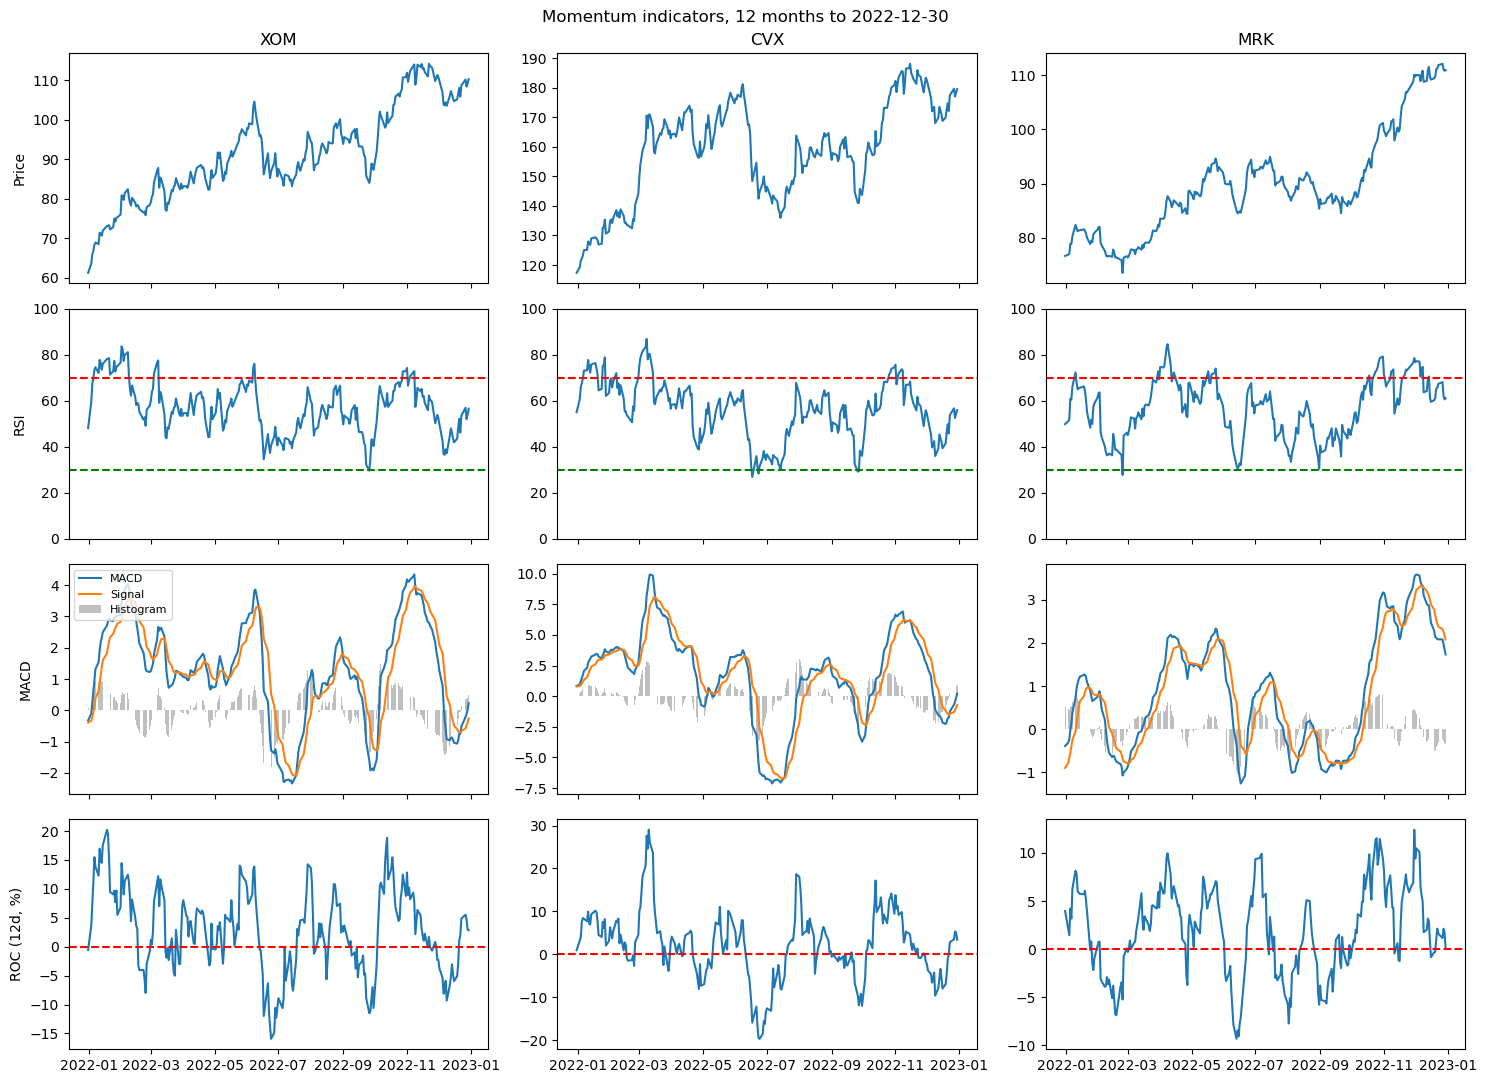

In [7]:
# Momentum indicators for the three strongest selected stocks (last 12 months to the formation date)
show = selected.index[:3]
fig, axes = plt.subplots(4, len(show), figsize=(15, 11), sharex="col")
for j, t in enumerate(show):
    s = prices.loc[:FIRST, t].dropna()
    line, signal = macd(s)
    roc = s.pct_change(12) * 100
    r = rsi(s)
    w = s.index[-MOM_LOOKBACK:]
    axes[0, j].plot(w, s[w]); axes[0, j].set_title(t)
    axes[1, j].plot(w, r[w]); axes[1, j].axhline(70, color="r", ls="--"); axes[1, j].axhline(30, color="g", ls="--"); axes[1, j].set_ylim(0, 100)
    axes[2, j].plot(w, line[w], label="MACD"); axes[2, j].plot(w, signal[w], label="Signal")
    axes[2, j].bar(w, (line - signal)[w], color="grey", alpha=0.5, label="Histogram")
    axes[3, j].plot(w, roc[w]); axes[3, j].axhline(0, color="r", ls="--")
for ax, label in zip(axes[:, 0], ["Price", "RSI", "MACD", "ROC (12d, %)"]):
    ax.set_ylabel(label)
axes[2, 0].legend(loc="upper left", fontsize=8)
fig.suptitle(f"Momentum indicators, 12 months to {FIRST.date()}")
plt.tight_layout()
plt.show()

## 4. ARIMA return views

For each selected stock, `auto_arima` is fitted to its **quarterly log returns** up to the formation date. Returns are used rather than prices because prices are non-stationary, and there is no seasonal term because stock returns have no real quarterly seasonality. The one-quarter-ahead forecast, annualised, becomes that stock's view in Black-Litterman.

In [8]:
def quarterly_log_returns(date, ticker):
    q = prices.loc[:date, ticker].dropna().resample(pd.offsets.QuarterEnd()).last()
    return np.log(q).diff().dropna()


def arima_view(date, ticker):
    q = quarterly_log_returns(date, ticker)
    # auto_arima picks the order; the stepwise search can still drop the intercept on AIC,
    # which makes a (0,0,0) model forecast exactly 0, so refit the chosen order with it forced on
    order = auto_arima(q, seasonal=False, max_p=3, max_q=3,
                       suppress_warnings=True, error_action="ignore").order
    model = ARIMA(order=order, with_intercept=True, suppress_warnings=True).fit(q)
    fc, ci = model.predict(1, return_conf_int=True)
    fc = float(np.asarray(fc)[0])
    return {"view_annual": np.exp(4 * fc) - 1, "fc_quarter": fc,
            "ci_low": ci[0][0], "ci_high": ci[0][1], "order": model.order}


views = pd.DataFrame({t: arima_view(FIRST, t) for t in selected.index}).T
views[["view_annual", "fc_quarter", "ci_low", "ci_high"]] = views[["view_annual", "fc_quarter", "ci_low", "ci_high"]].astype(float)
views

,view_annual,fc_quarter,ci_low,ci_high,order
XOM,0.0469,0.0115,-0.2310,0.2539,"(0, 0, 0)"
CVX,-0.0827,-0.0216,-0.2514,0.2082,"(1, 0, 0)"
MRK,0.0305,0.0075,-0.2127,0.2277,"(0, 0, 0)"
LLY,0.1606,0.0372,-0.1589,0.2334,"(3, 1, 1)"
TMUS,0.0498,0.0121,-0.3593,0.3836,"(0, 0, 0)"
BMY,0.0119,0.0030,-0.2283,0.2342,"(0, 0, 0)"
ABBV,-0.0472,-0.0121,-0.2241,0.2000,"(1, 0, 0)"
RTX,-0.0741,-0.0192,-0.2660,0.2275,"(0, 0, 1)"
UNH,0.2062,0.0469,-0.1981,0.2918,"(0, 0, 0)"
KO,0.0109,0.0027,-0.1511,0.1565,"(3, 0, 0)"


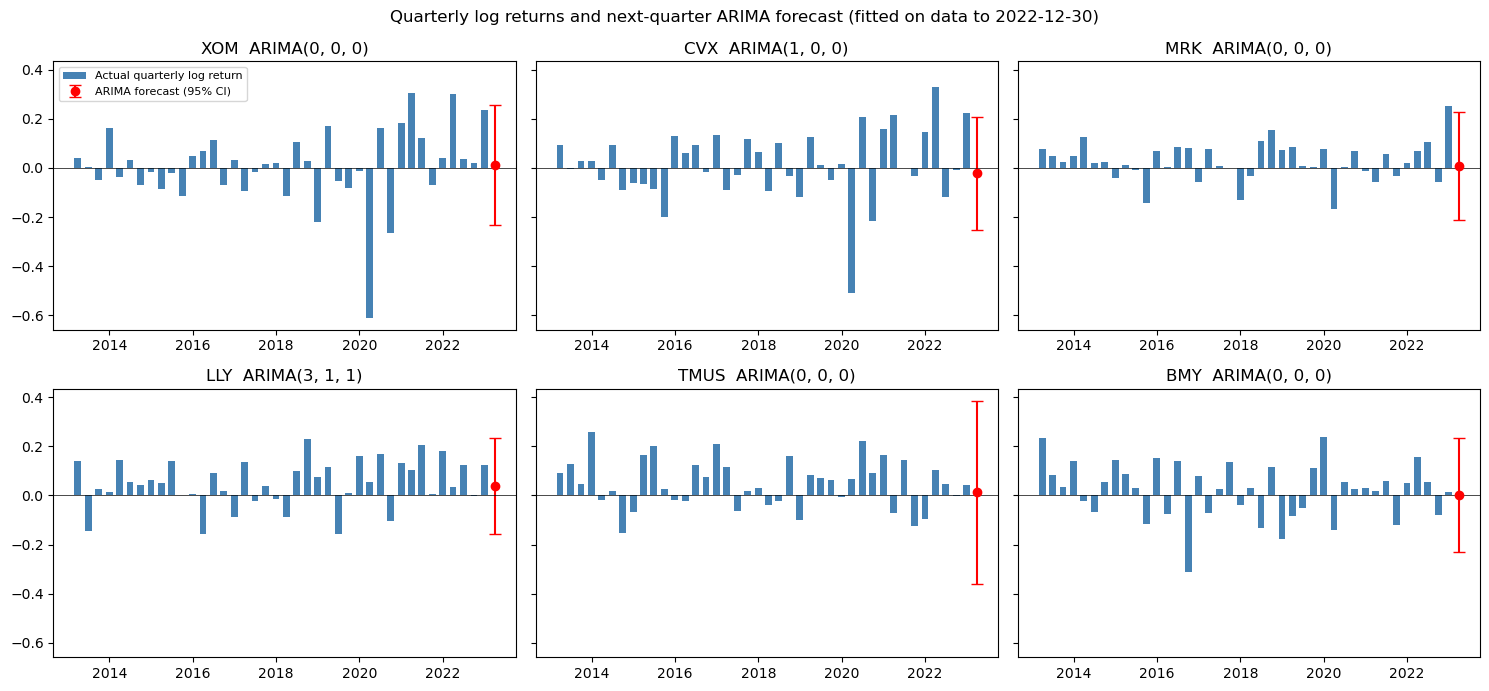

In [9]:
# History and forecast for six of the selected stocks
show = selected.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, t in zip(axes.flat, show):
    q = quarterly_log_returns(FIRST, t).iloc[-40:]
    nxt = q.index[-1] + pd.offsets.QuarterEnd()
    ax.bar(q.index, q.values, width=60, color="steelblue", label="Actual quarterly log return")
    v = views.loc[t]
    ax.errorbar([nxt], [v.fc_quarter], yerr=[[v.fc_quarter - v.ci_low], [v.ci_high - v.fc_quarter]],
                fmt="o", color="red", capsize=4, label="ARIMA forecast (95% CI)")
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(f"{t}  ARIMA{v.order}")
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Quarterly log returns and next-quarter ARIMA forecast (fitted on data to {FIRST.date()})")
plt.tight_layout()
plt.show()

## 5. Black-Litterman allocation

All quantities are **annual excess returns** over the risk-free rate.

* Covariance: $\Sigma$ = sample covariance of 3 years of daily returns × 252
* Risk aversion: $\delta = \text{MRP} / (w_{mkt}^\top \Sigma\, w_{mkt})$
* Prior (implied returns): $\pi = \delta\, \Sigma\, w_{mkt}$, where $w_{mkt}$ are market-cap weights
* Views: one absolute view per stock ($P = I$), $Q$ = ARIMA forecast − risk-free rate, with uncertainty $\Omega = \text{diag}(P\, \tau\Sigma\, P^\top)$ (He & Litterman)
* Posterior mean: $\mu_{BL} = \pi + \tau\Sigma P^\top (P\,\tau\Sigma\,P^\top + \Omega)^{-1}(Q - P\pi)$
* Posterior covariance: $\Sigma_{BL} = \Sigma + \left[(\tau\Sigma)^{-1} + P^\top\Omega^{-1}P\right]^{-1}$

Weights maximise the Sharpe ratio $w^\top\mu_{BL} / \sqrt{w^\top\Sigma_{BL}w}$, long-only, fully invested, each weight at most `MAX_WEIGHT`. If no stock has a positive expected excess return, the minimum-variance portfolio is used instead.

Every vector stays labelled by ticker, so weights cannot get attached to the wrong stock.

In [10]:
def black_litterman(date, tickers, caps, views):
    rets = prices.loc[:date, tickers].iloc[-COV_LOOKBACK:].pct_change(fill_method=None)
    tickers = list(rets.columns[rets.notna().mean() > 0.8])   # need 80% of the covariance window
    rets = rets[tickers]

    Sigma = rets.cov().values * 252
    w_mkt = (caps[tickers] / caps[tickers].sum()).values
    delta = MARKET_RISK_PREMIUM / (w_mkt @ Sigma @ w_mkt)
    pi = delta * Sigma @ w_mkt

    P = np.eye(len(tickers))
    Q = np.array([views[t] for t in tickers]) - RISK_FREE
    tS = TAU * Sigma
    Omega = np.diag(np.diag(P @ tS @ P.T))

    mu_bl = pi + tS @ P.T @ np.linalg.solve(P @ tS @ P.T + Omega, Q - P @ pi)
    Sigma_bl = Sigma + np.linalg.inv(np.linalg.inv(tS) + P.T @ np.linalg.inv(Omega) @ P)

    n = len(tickers)
    if mu_bl.max() > 0:
        objective = lambda w: -(w @ mu_bl) / np.sqrt(w @ Sigma_bl @ w)
    else:
        objective = lambda w: w @ Sigma_bl @ w
    result = minimize(objective, np.full(n, 1 / n), method="SLSQP",
                      bounds=[(0, MAX_WEIGHT)] * n,
                      constraints=({"type": "eq", "fun": lambda w: w.sum() - 1},))
    weights = np.clip(result.x, 0, None)
    weights /= weights.sum()

    return pd.DataFrame({
        "weight": weights, "w_mkt": w_mkt, "prior_pi": pi, "view_Q": Q,
        "posterior_mu": mu_bl, "volatility": np.sqrt(np.diag(Sigma_bl)),
    }, index=tickers)


bl = black_litterman(FIRST, list(selected.index), uni, views["view_annual"])
held = bl[bl["weight"] > 0.001].sort_values("weight", ascending=False)
print(f"Holding {len(held)} of {len(bl)} stocks on {FIRST.date()}")
held

Holding 6 of 25 stocks on 2022-12-30


,weight,w_mkt,prior_pi,view_Q,posterior_mu,volatility
V,0.2000,0.0604,0.0613,0.1619,0.1036,0.3369
MA,0.2000,0.0460,0.0674,0.2664,0.1217,0.3788
PG,0.2000,0.0494,0.0384,0.2640,0.0862,0.2434
UNH,0.1893,0.0682,0.0582,0.1762,0.0780,0.3326
LLY,0.1318,0.0478,0.0448,0.1306,0.0595,0.3479
COST,0.0789,0.0279,0.0369,0.0223,0.0452,0.2727


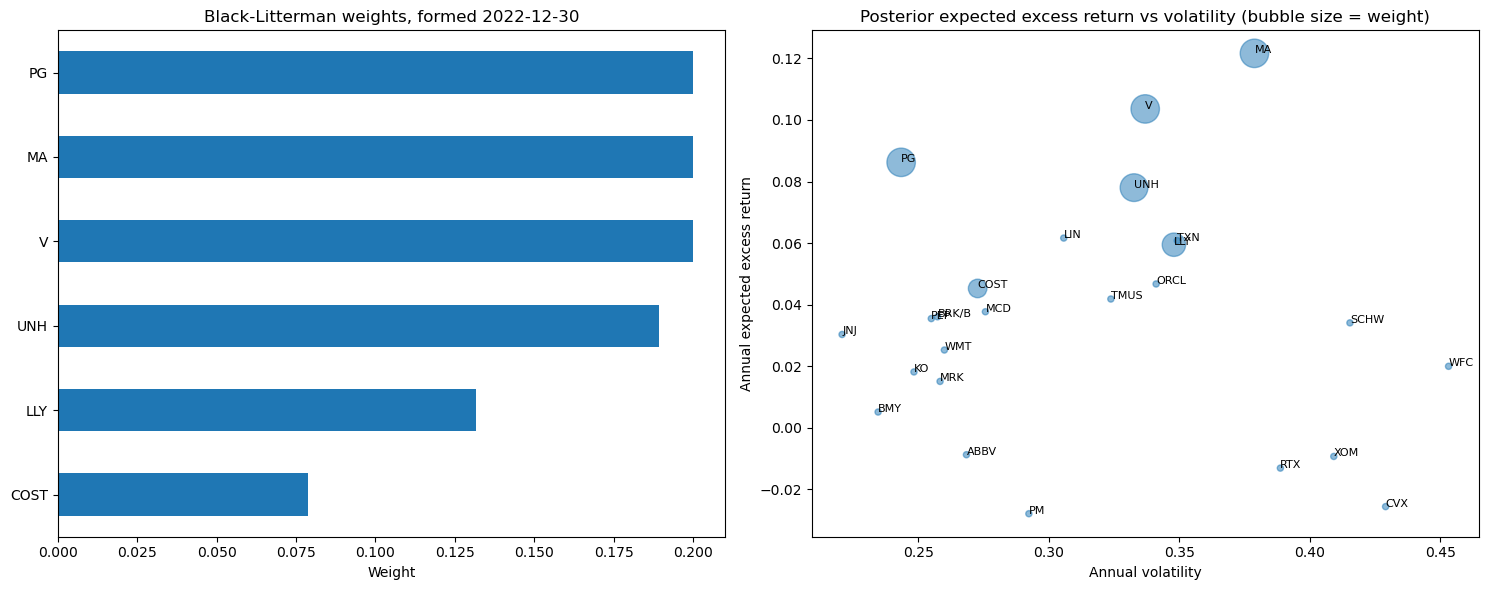

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
held["weight"].sort_values().plot(kind="barh", ax=ax1)
ax1.set_title(f"Black-Litterman weights, formed {FIRST.date()}")
ax1.set_xlabel("Weight")

ax2.scatter(bl["volatility"], bl["posterior_mu"], s=20 + bl["weight"] * 2000, alpha=0.5)
for t, row in bl.iterrows():
    ax2.annotate(t, (row["volatility"], row["posterior_mu"]), fontsize=8)
ax2.set_title("Posterior expected excess return vs volatility (bubble size = weight)")
ax2.set_xlabel("Annual volatility")
ax2.set_ylabel("Annual expected excess return")
plt.tight_layout()
plt.show()

## 6. Walk-forward backtest: 2023

On each formation date the full pipeline (universe → momentum selection → ARIMA views → Black-Litterman) is re-run using only data up to that date. The weights are then held, buy-and-hold, until the next formation date. If a stock stops trading mid-quarter, its last price is carried forward.

**Benchmarks**, also rebalanced quarterly:

* **Equal-weight top 50:** the same universe, equally weighted
* **Cap-weight top 50:** the same universe, weighted by market cap
* **Cap-weight S&P 500:** all index members by market cap, a proxy for the S&P 500 price index

All returns are price returns (dividends are not included).

In [12]:
def hold(start, end, weights):
    p = prices.loc[start:end, weights.index].ffill()
    return (p / p.iloc[0]) @ weights


def backtest(start, end, verbose=True):
    dates = formation_dates(start, end)
    ends = dates[1:] + [prices.loc[:end].index[-1]]
    names = ["Strategy", "Equal-weight top 50", "Cap-weight top 50", "Cap-weight S&P 500"]
    curves = {k: [] for k in names}
    level = {k: 1.0 for k in names}
    allocations = {}

    for f, f_next in zip(dates, ends):
        uni = universe(f)
        sel = select_stocks(f, uni)
        v = {t: arima_view(f, t)["view_annual"] for t in sel.index}
        bl = black_litterman(f, list(sel.index), uni, v)
        sp = universe(f, size=10_000)
        weights = {
            "Strategy": bl["weight"],
            "Equal-weight top 50": pd.Series(1 / len(uni), index=uni.index),
            "Cap-weight top 50": uni / uni.sum(),
            "Cap-weight S&P 500": sp / sp.sum(),
        }
        for k, w in weights.items():
            c = hold(f, f_next, w) * level[k]
            level[k] = c.iloc[-1]
            curves[k].append(c if not curves[k] else c.iloc[1:])
        allocations[f] = bl["weight"]
        if verbose:
            top = bl["weight"].sort_values(ascending=False).head(3)
            print(f"{f.date()} -> {f_next.date()}: {int((bl['weight'] > 0.001).sum())} holdings, "
                  f"top: {', '.join(f'{t} {w:.0%}' for t, w in top.items())}")

    curves = pd.DataFrame({k: pd.concat(v) for k, v in curves.items()})
    return curves, pd.DataFrame(allocations).fillna(0)


def performance(curves):
    out = {}
    for k, v in curves.items():
        r = v.pct_change().dropna()
        years = (v.index[-1] - v.index[0]).days / 365.25
        vol = r.std() * np.sqrt(252)
        out[k] = {
            "Total return": v.iloc[-1] / v.iloc[0] - 1,
            "CAGR": (v.iloc[-1] / v.iloc[0]) ** (1 / years) - 1,
            "Volatility": vol,
            "Sharpe": (r.mean() * 252 - RISK_FREE) / vol,
            "Max drawdown": (v / v.cummax() - 1).min(),
        }
    return pd.DataFrame(out).T


curves_2023, alloc_2023 = backtest(TEST_START, TEST_END)
perf_2023 = performance(curves_2023)
perf_2023.style.format("{:.2%}").format("{:.2f}", subset=["Sharpe"])

2022-12-30 -> 2023-03-31: 6 holdings, top: PG 20%, MA 20%, V 20%
2023-03-31 -> 2023-06-30: 10 holdings, top: ABBV 20%, TXN 20%, LLY 20%
2023-06-30 -> 2023-09-29: 8 holdings, top: MA 20%, V 20%, NFLX 20%
2023-09-29 -> 2023-12-29: 11 holdings, top: LLY 20%, MSFT 20%, MRK 20%


,Total return,CAGR,Volatility,Sharpe,Max drawdown
Strategy,12.67%,12.72%,13.29%,0.75,-8.74%
Equal-weight top 50,23.06%,23.15%,12.38%,1.51,-9.70%
Cap-weight top 50,37.03%,37.18%,14.96%,2.00,-8.71%
Cap-weight S&P 500,25.56%,25.66%,13.31%,1.57,-10.03%


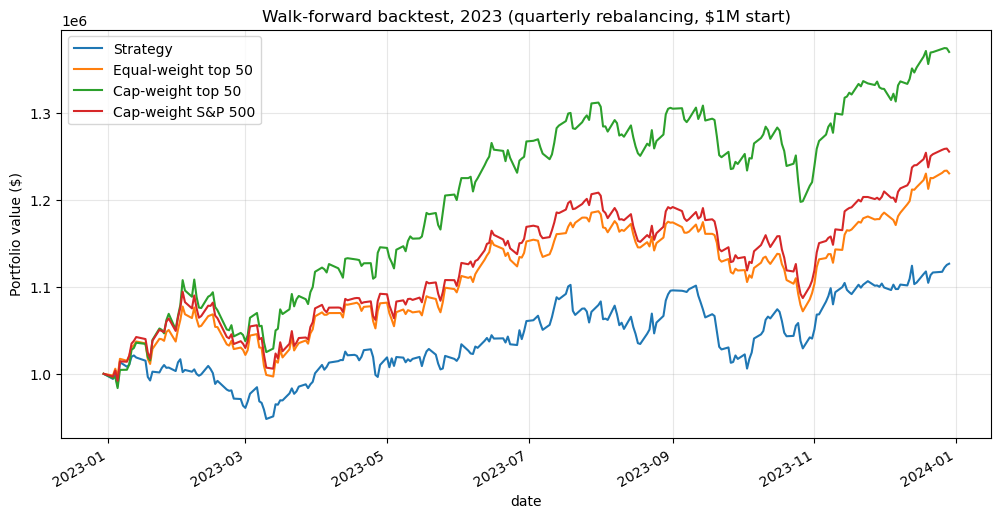

Final values:
Strategy               $1,126,712
Equal-weight top 50    $1,230,604
Cap-weight top 50      $1,370,315
Cap-weight S&P 500     $1,255,648


In [13]:
START_VALUE = 1_000_000
(curves_2023 * START_VALUE).plot(figsize=(12, 6), title="Walk-forward backtest, 2023 (quarterly rebalancing, $1M start)")
plt.ylabel("Portfolio value ($)")
plt.grid(alpha=0.3)
plt.show()

print("Final values:")
print((curves_2023.iloc[-1] * START_VALUE).map("${:,.0f}".format).to_string())

In [14]:
# Strategy weights at each rebalance (stocks held at least once)
alloc = alloc_2023.loc[(alloc_2023 > 0.001).any(axis=1)]
alloc.columns = [d.date() for d in alloc.columns]
alloc.sort_values(alloc.columns[0], ascending=False).style.format("{:.1%}")

,2022-12-30,2023-03-31,2023-06-30,2023-09-29
MA,20.0%,3.4%,20.0%,4.7%
V,20.0%,2.9%,20.0%,17.7%
PG,20.0%,0.0%,0.0%,0.0%
UNH,18.9%,8.1%,0.0%,0.0%
LLY,13.2%,20.0%,0.0%,20.0%
COST,7.9%,0.0%,0.0%,0.0%
ABBV,0.0%,20.0%,0.0%,0.0%
MCD,0.0%,0.0%,3.4%,0.0%
WMT,0.0%,0.0%,0.0%,9.7%
HD,0.0%,12.5%,0.0%,0.0%


## 7. Robustness: 2010–2023

One year is only four rebalances, too few to judge a strategy. The same walk-forward process run over 14 years (56 rebalances) gives a fairer picture.

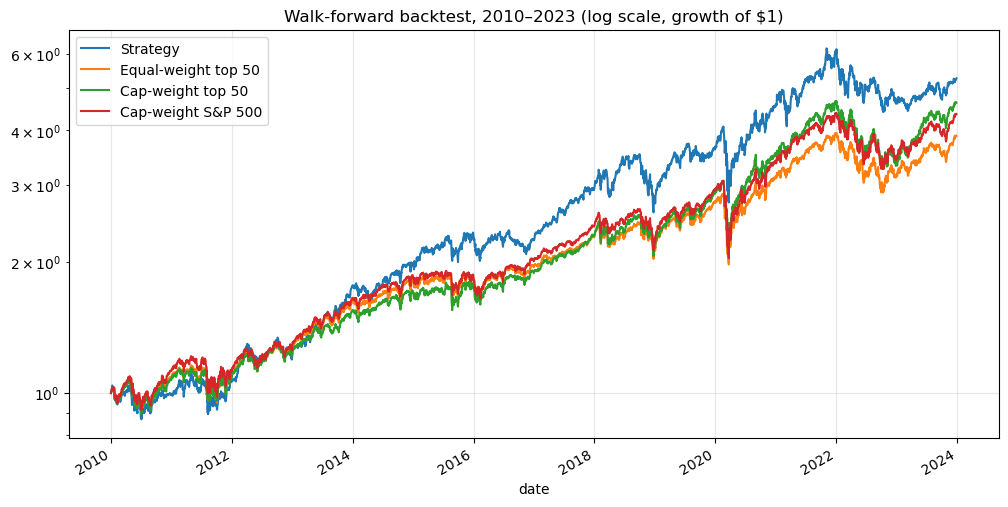

,Total return,CAGR,Volatility,Sharpe,Max drawdown
Strategy,426.61%,12.61%,20.48%,0.54,-33.03%
Equal-weight top 50,288.60%,10.19%,16.81%,0.48,-31.08%
Cap-weight top 50,362.98%,11.57%,17.88%,0.54,-30.03%
Cap-weight S&P 500,335.59%,11.09%,17.53%,0.52,-33.57%


,Strategy,Equal-weight top 50,Cap-weight top 50,Cap-weight S&P 500
date,,,,
2010,-0.8%,8.7%,7.3%,12.3%
2011,7.1%,0.6%,1.6%,-0.0%
2012,14.5%,14.6%,12.9%,13.4%
2013,45.3%,29.8%,26.0%,29.7%
2014,10.7%,10.3%,9.1%,11.0%
2015,17.4%,2.2%,3.8%,0.1%
2016,-2.5%,6.0%,7.2%,9.0%
2017,30.5%,17.1%,21.3%,20.1%
2018,-3.3%,-4.5%,-3.3%,-5.9%


In [15]:
if RUN_LONG_BACKTEST:
    curves_long, alloc_long = backtest(LONG_START, LONG_END, verbose=False)
    perf_long = performance(curves_long)
    curves_long.plot(figsize=(12, 6), logy=True, title="Walk-forward backtest, 2010–2023 (log scale, growth of $1)")
    plt.grid(alpha=0.3)
    plt.show()

    yearly = curves_long.resample(pd.offsets.YearEnd()).last().pct_change().dropna()
    yearly.index = yearly.index.year
    display(perf_long.style.format("{:.2%}").format("{:.2f}", subset=["Sharpe"]))
    display(yearly.style.format("{:.1%}"))

## 8. Findings

**2023 (test year, 4 rebalances):** the strategy returned **12.7%** and **underperformed every benchmark**. The S&P 500 proxy returned 25.6%, and the cap-weighted top 50 returned 37.0% (driven by the mega-cap rally in AAPL, MSFT, NVDA and META). Momentum measured at the end of 2022 pointed towards energy and defensive stocks, which lagged in 2023.

**2010–2023 (56 rebalances):**

| | CAGR | Volatility | Sharpe | Max drawdown |
|---|---|---|---|---|
| Strategy | 12.6% | 20.5% | 0.54 | −33.0% |
| Equal-weight top 50 | 10.2% | 16.8% | 0.48 | −31.1% |
| Cap-weight top 50 | 11.6% | 17.9% | 0.54 | −30.0% |
| Cap-weight S&P 500 | 11.1% | 17.5% | 0.52 | −33.6% |

The strategy earned about 1.5 percentage points a year more than the S&P 500 proxy, but with more volatility. Its Sharpe ratio is the **same** as simply holding the 50 largest stocks by market cap, so on a risk-adjusted basis there is **no evidence of an edge**.

**Caveats**

* **Fragile results.** One modelling detail (whether ARIMA includes an intercept) moved the 2023 return from 19% to 13%. Results that sensitive should not be relied on.
* **Price returns only.** Dividends are excluded for all portfolios, so absolute returns are understated.
* **No transaction costs.** The strategy turns over far more than the benchmarks.
* **Some settings chosen after seeing results.** The 20% weight cap was added after seeing the uncapped optimiser put 60% into a single stock, so it is not fully out-of-sample.
* **Weak ARIMA views.** The 95% intervals on quarterly returns are roughly ±20–35%, so the views carry little information. Most of the allocation comes from the momentum selection and the covariance matrix.

The Phase 1 version of this notebook reported a Sharpe ratio of 12.91. That figure came from the bugs listed in the README and has no meaning.